# 第 1 册 · 从买西瓜到期末复习

> 主角：爱提问的奶牛猫**团子** × 屋檐下的**老橘师傅**。对应《西瓜书》第 1~2 章，联动仓库笔记 [线性回归的实现.ipynb](../线性回归的实现.ipynb)。

![第 1 幕：买西瓜与租房子的特征、标签、模型](../assets/pic01-watermelon-stall.svg)

## 一、电脑没有舌头，怎么挑瓜

团子问老橘师傅：人挑瓜能拍一拍听声，租房子能去看采光，电脑凭什么？

老橘师傅说，路数和人一模一样，分三步。

**看线索**：瓜蒂弯不弯、纹路清不清、拍着脆不脆；房子多大、离地铁几分钟、朝不朝南。这些能观察到的量叫**特征**，记作 $x$。

**对答案**：瓜切开到底甜不甜，房子最后成交多少。这种事后才知道的结果叫**标签**，记作 $y$。

**攒经验**：把几百次挑瓜看房的旧账翻一遍，摸出一张打分卡——瓜蒂弯曲加 20 分，拍着脆响加 50 分，离地铁近加 30 分。这张卡就是**模型** $f(x)$。

到这里都平平无奇，真正的分水岭在下一节。

## 二、背下 15 道模拟题，能拿满分吗

团子出了个主意：把 15 道模拟题连答案带卷面全背死，连第 8 题右上角的印刷脏墨点都记下来——「凡是有墨点的题，一律选 B」。

老橘师傅说，你班里肯定有这三种同学。

第一种，平时不翻书，考卷一律全蒙 C。等于拿直尺画波浪，规律压根没摸着，这叫**欠拟合**。

第二种，就是团子说的背墨点选手。模拟卷满分，第二天拿到干净的新卷子，当场不及格。把噪声当规律死记下来，叫**过拟合**。

第三种，知道墨点只是巧合，只抓解题的大规律，换什么卷子都稳。

![第 2 幕：期末复习的三种同学](../assets/pic02-three-apprentices.svg)

<details>
<summary><b>课本批注 · 偏差-方差分解与双下降（《西瓜书》2.5 节）</b></summary>

期末考新卷的总错分可以拆成三份：**偏差平方** $\text{Bias}^2$（脑子太死板，全蒙 C 的那一位）+ **方差** $\text{Variance}$（太敏感，连墨点都背的那一位）+ **噪声**（卷子本身的印刷误差）。

那现在百亿参数的大模型，为什么没有变成背墨点的书呆子？这要用**双下降**（double descent）来看：参数个数 $P$ 恰好等于题目数 $N=15$ 时，能穿过所有墨点的曲线只有一条，它被拧得剧烈变形，测试误差冲上顶峰；等 $P$ 远大于 $N$（比如 $P=110$），能拿满分的曲线有无穷多条，梯度下降会自动挑中最平缓的那条，测试误差反而**第二次下降**。下面第二张图右半段就是这条「双下降」尾巴。

</details>

## 三、动手跑一跑

下面这段代码让三种同学同台考试：全蒙直线（1 阶）、摸清规律（4 阶）、死背墨点（14 阶），再补一位 110 个参数的大模型选手，看它在 80 道新题上的表现。跑完后重点看两张图：拟合形状，以及误差随参数量变化的曲线。

🐾 【老橘师傅与团子的实验成绩单 (15 道旧题复习，80 道期末新题盲测)】
  1. 偷懒蒙直线 (欠拟合)        -> 偏差平方 = 0.4778, 方差 = 0.0055, 期末总错分 = 0.5316 (连基本规律都没看懂)
  2. 摸清套路 (4阶平滑弧线)     -> 偏差平方 = 0.0836, 方差 = 0.0125, 期末总错分 = 0.1444 (忽略印刷墨点，全场最准!)
  3. 死背印刷墨点 (12阶过拟合)  -> 偏差平方 = 0.0007, 方差 = 0.1862, 期末总错分 = 0.2353 (换张新卷子全傻眼!)
  4. 过参数化大模型 (110个旋钮自动选最平缓曲线) -> 旧题误差 = 0.01168, 新题误差重新降回 = 0.0812!

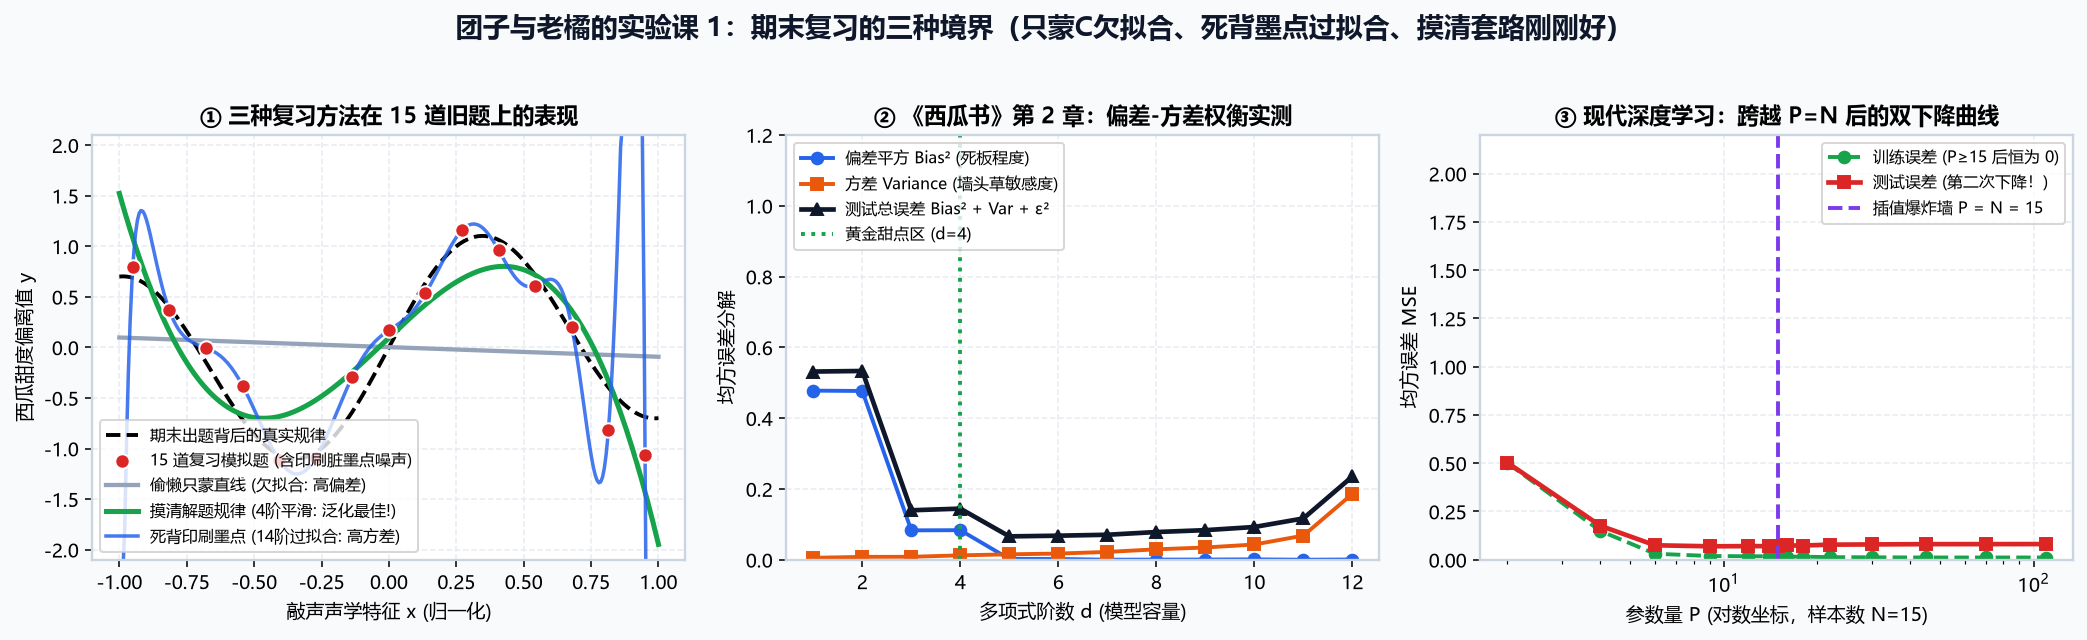

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander

# 1. 老橘师傅出 15 道复习模拟题 (含印刷脏墨点随机误差)
np.random.seed(42)
true_fn = lambda x: np.sin(1.5 * np.pi * x) + 0.3 * x
N = 15
x_train = np.linspace(-0.95, 0.95, N)
y_train = true_fn(x_train) + np.random.normal(0, 0.22, size=N)

# 2. 同台对比：偷懒蒙直线(1阶) vs 摸清规律(4阶) vs 死背印刷墨点(14阶) vs 110参数大模型
print("🐾 正在开始期末模拟考与 80 道新题盲测...")

## 老橘师傅带你看懂结果

左图里，红色圆点是 15 道带墨点的模拟题。蓝线（14 阶）为了强行穿过每一个点，在点与点之间剧烈上下抽风——这就是过拟合的样子；绿线（4 阶）大体贴着规律走，最从容。

中图是误差随模型容量变化的曲线。模型太简单，偏差大；太复杂，方差大；`d=4` 附近的绿色虚线是两头兼顾的甜点区。

右图最有意思：跨过 15 道题的插值边界之后，110 参数的大模型测试误差先冲高、再回落——测试误差的**第二次下降**，就是双下降。它不是玄学：参数多到用不完时，最小范数解天然偏向「最平缓」的那条曲线。